For a catalyzed reaction occuring inside the sphere that is reaction rate-limited (i.e., reactant diffuses into the sphere more quickly than it is consumed by the reaction), the heat generated from the reaction will be constant. The resulting partial differential equation is

$$
\frac{1}{\alpha} \frac{\partial T(r,t)}{\partial t} =
\frac{\partial^2 T(r,t)}{\partial r^2} 
+ \frac{2}{r} \frac{\partial T(r,t)}{\partial r}
+ \frac{H_{gen}}{k}
$$

where 
$\alpha$ is the thermal diffusivity,
$H_{gen}$ is the heat generated from the reaction,
and
$k$ is the thermal conductivity. The boundary conditions are

$$
\begin{align}
\frac{\partial T(0,t)}{\partial r} &= 0 \\
-k\frac{\partial T(R,t)}{\partial r} &= h\ (T(R,t) - T_b)
\end{align}
$$

where
$R$ is the radius of the particle,
$h$ is the convection coefficient,
and
$T_b$ is the bulk temperature of the reactor gas.

Plot the temperature profiles for a 1 cm diameter ceramic particle ($\alpha$ = 0.1 mm$^2$/s, $k$ = 0.12 W/m/K) that generates heat at a rate of $H_{gen}$ = 3 kW/L. The reactor gas has a bulk temperature of $T_b$ = 300°C and a convection coefficient $h$ = 10 W/m/K. The particle is initially at a uniform temperature $T_i$ = 300°C.

Sample output is given below.

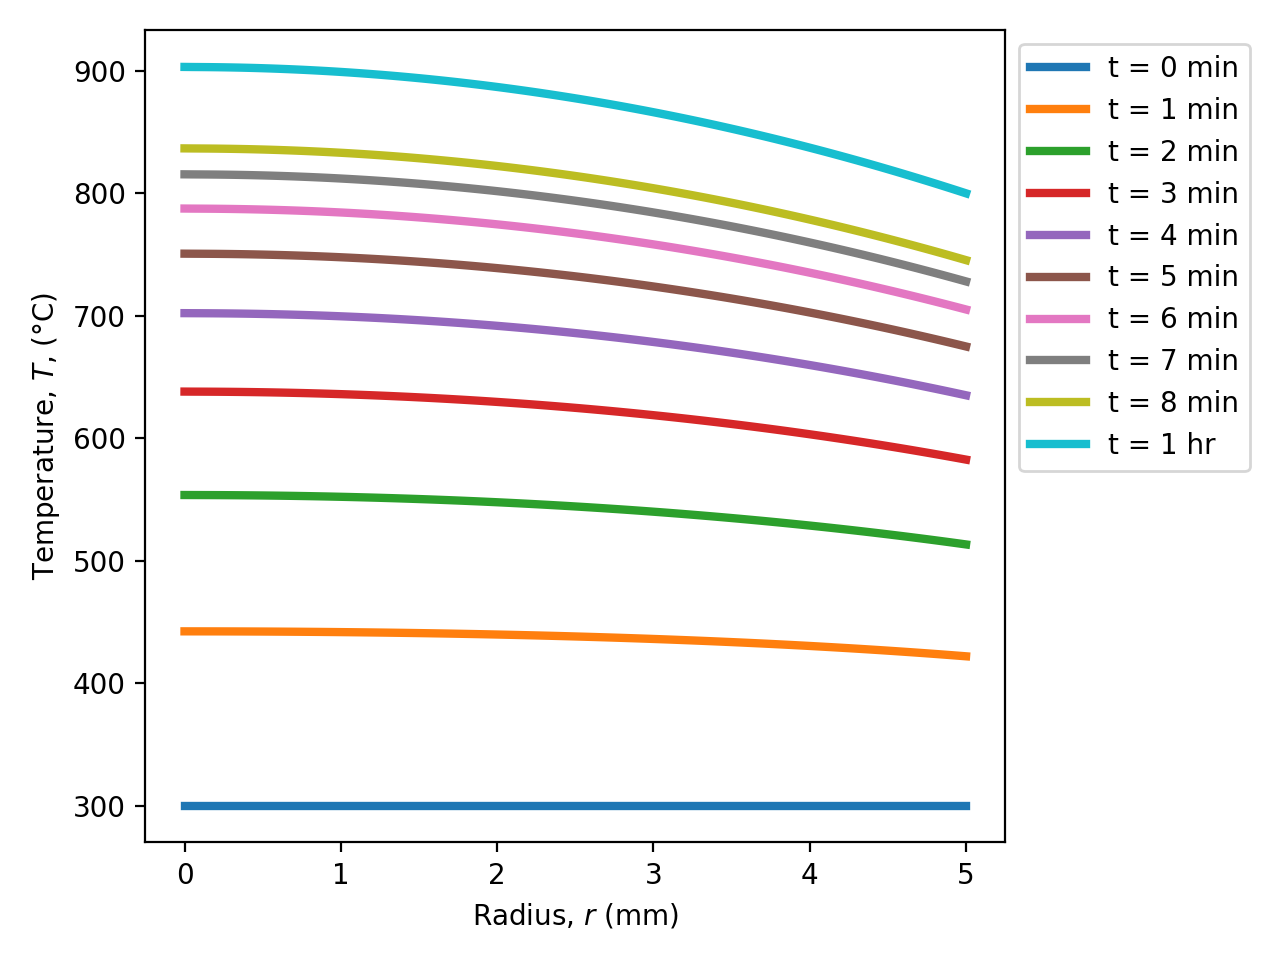

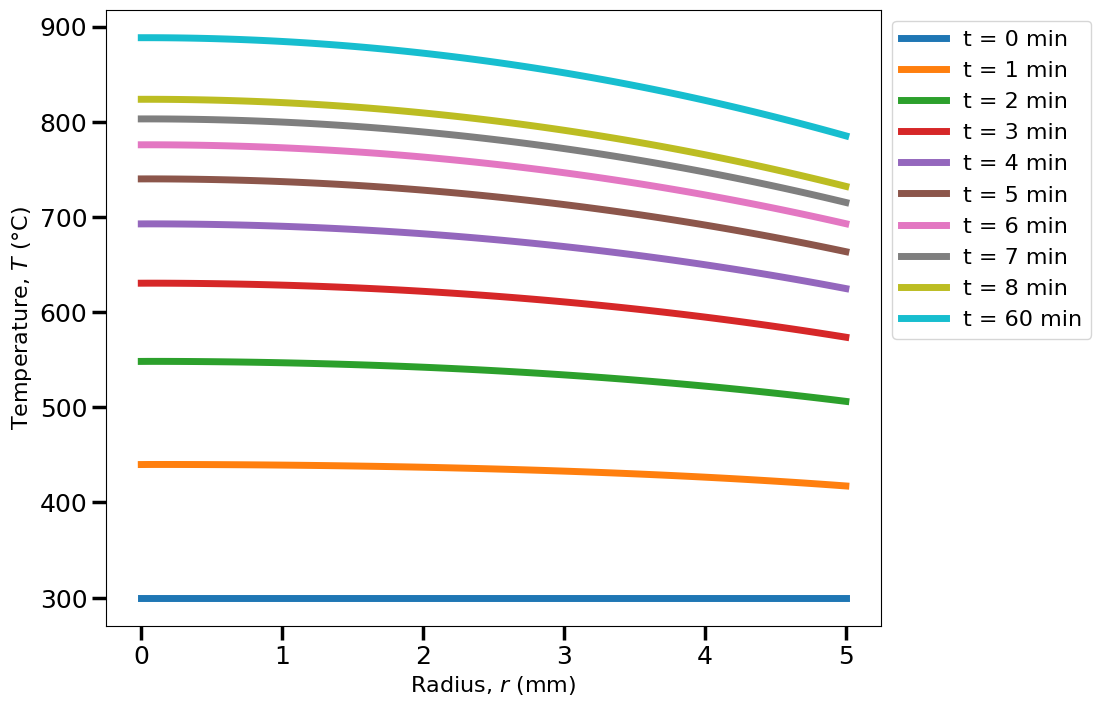

In [36]:
# import modules
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as intx

# define constants
# internal units
# Length = mm
# Temperature = °C
# Time = s
# Power = W

# unit conversions
u_to_m = 1.e3
min_to_s = 60
Kw_to_w = .001

# Heat Generation
Hgen = 3*Kw_to_w #Kw/L

# ceramic properties
alpha = 0.1 # mm^2/s
k = 0.12 / u_to_m # W/mm/K

# air properties
h = 10 / u_to_m**2 # W/mm^2/K

# boundary conditions
Tb = 300 # fluid temperature

# initial conditions
Ti = 300

# discretize space
Nr = 100
rmin,rmax = 0,5
r = np.linspace(rmin,rmax,Nr)
dr = r[1] - r[0]
dr2 = dr*dr

# discretize time
Nt = 10
tmin,tmax = 0,9*min_to_s
t = np.linspace(0,tmax,Nt)
t[-1] = 60 * min_to_s

# define functions
def pde(T,t):
    dTdt = np.zeros_like(T)
    
    # inner boundary
    dTdr = 0
    dTdt[0] = alpha * ((T[1]-T[0])/dr - dTdr)/dr
    
    # interior boundary
    for i in range(1,Nr-1):
        dTdt[i] = alpha * ((T[i+1] - 2*T[i] + T[i-1])/dr2 +
                           2/r[i] * (T[i+1]-T[i])/dr + Hgen/k)
    
    # outer boundary
    dTdr = -h/k*(T[-1] - Tb)
    dT = T[-1] - T[-2]
    dTdt[-1] = alpha * ((dTdr - dT/dr)/dr + 2/r[-1] * dTdr)
    
    return dTdt
    
# main code
T0 = np.ones(Nr) * Ti

T = intx.odeint(pde,T0,t)

# plot results
plt.figure(figsize=(10,8))
for it,ti in enumerate(t):
    plt.plot(r,T[it,:],'-',lw=5,label='t = %.0f min' % (ti/min_to_s))

plt.xlabel('Radius, $r$ (mm)',fontsize = 16)
plt.ylabel('Temperature, $T$ (°C)',fontsize = 16)
plt.legend(loc='upper left',bbox_to_anchor=(1.0,1.0),fontsize = 16)
plt.tick_params(axis='both', which='major', labelsize=18, width=2.5, length=10)
plt.show()